# 🧭 Introduction to Data Analysis: a first look at NileCart

**Zero Grad · Data Analysis course · Foundations**

> 📖 **The lesson (in Arabic), with diagrams and interactive charts:** [zero-grad.com/courses/da/intro](https://zero-grad.com/courses/da/intro/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *Introduction* lesson.
The lesson page explains the ideas: what data analysis is, the workflow, and the types of data.
Here we open the data for the first time and take one real question through the whole workflow.

**The data:** NileCart, an online shop in Cairo that sells electronics, accessories, office furniture and stationery, and delivers all over Egypt. Prices are in EGP.

Don't worry if some of the code is new.
Every line here is explained in detail in the NumPy and Pandas lessons.
For now, read it, run it, and look at what comes out.

| # | Part | What we do |
|---|---|---|
| 1 | The data as a table | Rows, columns, cells |
| 2 | Types of data | What kind of values each column holds |
| 3 | One chart per type | The type decides the chart |
| 4 | The workflow | One question: did NileCart grow in 2025? |
| 5 | The raw tables | Where `sales.csv` comes from, and what's wrong with the raw data |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/nilecart/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../data/nilecart")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])

---
# 1️⃣ The data as a table

The first three things to check on any new table: how big is it, what does it look like, and what are its columns?

In [2]:
sales.shape

(1466, 18)

**1,466 rows and 18 columns.**

In [3]:
sales.head()

,order_id,order_date,customer_id,name,governorate,region,segment,product_id,product_name,category,quantity,unit_price,discount,gross,revenue,unit_cost,profit,status
0,10002,2024-01-01,176,Fatma Hassan,Cairo,Greater Cairo,Consumer,111,Notebook,Stationery,5.00,63.00,0.00,315.00,315.00,20,215.00,cancelled
1,10001,2024-01-01,132,Yasmin Mostafa,Cairo,Greater Cairo,Corporate,101,Laptop,Electronics,9.00,"30,400.00",0.05,"273,600.00","259,920.00",27200,"15,120.00",completed
2,10004,2024-01-02,131,Yasmin Fawzy,Sharqia,Delta,Corporate,111,Notebook,Stationery,10.00,57.00,0.00,570.00,570.00,20,370.00,completed
3,10003,2024-01-02,5,Mahmoud Abdelrahman,Cairo,Greater Cairo,Small Business,111,Notebook,Stationery,5.00,60.00,0.05,300.00,285.00,20,185.00,shipped
4,10005,2024-01-02,13,Tarek Saleh,Cairo,Greater Cairo,Consumer,105,Keyboard,Accessories,4.00,"1,140.00",0.00,"4,560.00","4,560.00",600,"2,160.00",completed


A tidy table follows three rules:

- every **row** is one observation: here, one order line (one product, a quantity, a price),
- every **column** is one variable: `revenue`, `category`, `order_date`…,
- every **cell** holds one value.

One row, seen on its own:

In [4]:
sales.iloc[1]

order_id                      10001
order_date      2024-01-01 00:00:00
customer_id                     132
name                 Yasmin Mostafa
governorate                   Cairo
region                Greater Cairo
segment                   Corporate
product_id                      101
product_name                 Laptop
category                Electronics
quantity                       9.00
unit_price                30,400.00
discount                       0.05
gross                    273,600.00
revenue                  259,920.00
unit_cost                     27200
profit                    15,120.00
status                    completed
Name: 1, dtype: object

Customer 132 (a Corporate customer from Cairo) bought 9 laptops on the first day of 2024, with a 5% discount: 259,920 EGP.

---
# 2️⃣ Types of data

Before you compute or plot anything, ask: **what kind of values does this column hold?**
Pandas gives each column a **dtype**, which is how the values are *stored*:

In [5]:
sales.dtypes

order_id                 int64
order_date      datetime64[ns]
customer_id              int64
name                    object
governorate             object
region                  object
segment                 object
product_id               int64
product_name            object
category                object
quantity               float64
unit_price             float64
discount               float64
gross                  float64
revenue                float64
unit_cost                int64
profit                 float64
status                  object
dtype: object

The dtype is not the type of the data.
`customer_id` is stored as `int64`, but it's an identifier, not a quantity.
`quantity` is stored as `float64`, but it only holds whole numbers from 1 to 10.

The type comes from what the column **means**. Here is every column of NileCart, classified by hand:

In [6]:
kinds = {
    "order_id": "ID", "customer_id": "ID", "product_id": "ID",
    "order_date": "Datetime",
    "name": "Text",
    "governorate": "Nominal", "region": "Nominal", "segment": "Nominal",
    "product_name": "Nominal", "category": "Nominal", "status": "Nominal",
    "quantity": "Discrete", "discount": "Discrete",
    "unit_price": "Continuous", "gross": "Continuous", "revenue": "Continuous",
    "unit_cost": "Continuous", "profit": "Continuous",
}
types = pd.DataFrame({
    "kind": pd.Series(kinds),
    "dtype": sales.dtypes.astype(str),
    "unique values": sales.nunique(),
    "example": sales.iloc[0],
})
types.sort_values("kind")

,kind,dtype,unique values,example
unit_price,Continuous,float64,33,63.00
revenue,Continuous,float64,551,315.00
gross,Continuous,float64,281,315.00
profit,Continuous,float64,562,215.00
unit_cost,Continuous,int64,11,20
order_date,Datetime,datetime64[ns],605,2024-01-01 00:00:00
discount,Discrete,float64,4,0.00
quantity,Discrete,float64,10,5.00
product_id,ID,int64,11,111
customer_id,ID,int64,160,176


| Kind | Meaning | Chart that fits |
|---|---|---|
| **Continuous** | any value in a range, fractions too | histogram, box plot |
| **Discrete** | whole numbers you count | bar chart of counts |
| **Nominal** | groups with no order | bar chart |
| **Ordinal** | groups with an order (size S / M / L, a 1–5 rating) | bar chart, in that order |
| **Datetime** | a date or a time | line chart |
| **Text** | free text | cleaned, not plotted |
| **ID** | a number that names a row | counted, not computed on |

NileCart has no ordinal column. We'll make one later, when we cut revenue into small / medium / large orders.

## 2.1 Not every number is numerical

Pandas will happily average any number column.
That doesn't make the result meaningful:

In [7]:
print(sales["order_id"].mean())

10754.055934515689


The "average order id" is 10,754, and it means nothing.
An id only tells one order from another, like a national ID number.
What you *can* do with an id is count it:

In [8]:
print("orders:   ", sales["order_id"].nunique())
print("customers:", sales["customer_id"].nunique())
print("products: ", sales["product_id"].nunique())

orders:    1466
customers: 160
products:  11


## 2.2 A number with few values

`discount` is a number, but it only takes four values:

In [9]:
sales["discount"].value_counts().sort_index()

discount
0.00    752
0.05    330
0.10    204
0.20    180
Name: count, dtype: int64

0%, 5%, 10% or 20%. We treat it like a discrete column: count each value, don't draw a histogram.

---
# 3️⃣ One chart per type

The type of a column decides the chart.
One example of each, with Seaborn (the Visualization lessons go through every chart in detail, with all three libraries).

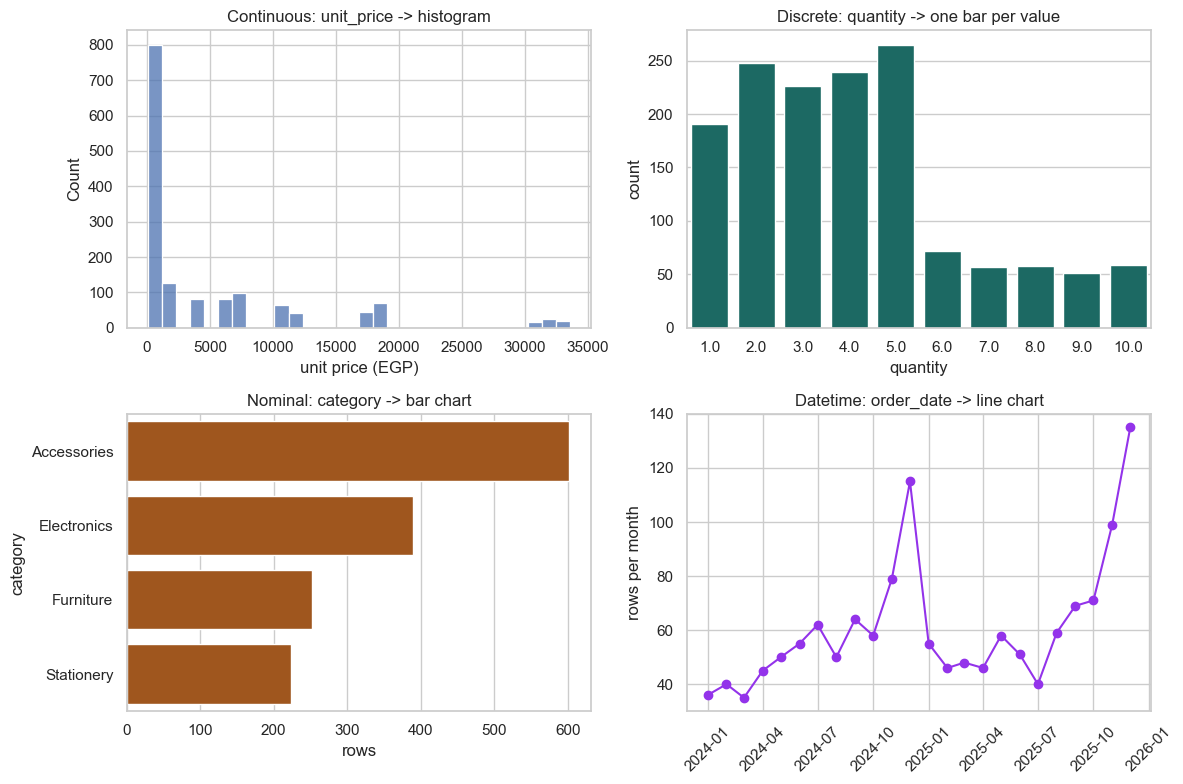

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=sales, x="unit_price", bins=30, ax=axes[0, 0])
axes[0, 0].set(title="Continuous: unit_price -> histogram", xlabel="unit price (EGP)")

sns.countplot(data=sales, x="quantity", color="#0f766e", ax=axes[0, 1])
axes[0, 1].set(title="Discrete: quantity -> one bar per value")

order = sales["category"].value_counts().index
sns.countplot(data=sales, y="category", order=order, color="#b45309", ax=axes[1, 0])
axes[1, 0].set(title="Nominal: category -> bar chart", xlabel="rows")

per_month = sales.set_index("order_date").resample("MS").size()
axes[1, 1].plot(per_month.index, per_month.values, marker="o", color="#9333ea")
axes[1, 1].set(title="Datetime: order_date -> line chart", ylabel="rows per month")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Four columns, four questions, four different charts:

- **unit_price:** most products are cheap, a few are very expensive (a long tail to the right).
- **quantity:** 1 to 5 pieces is common, 6 to 10 is rarer (only Corporate customers buy that much).
- **category:** Accessories and Electronics have the most order lines.
- **order_date:** a peak every November and December.

---
# 4️⃣ The workflow: one question, six steps

**Ask → Collect → Clean → Explore → Analyze → Communicate**

## Step 1 · Ask

The manager asks: ***Did NileCart grow in 2025?***

Grow in what? The number of orders? The money? The size of a typical order?
Each of these is a different **metric**, and we'll check all three.

## Step 2 · Collect

The data is `sales.csv`. For this question we need three columns: `order_date`, `revenue` and `status`.

In [11]:
sales[["order_id", "order_date", "revenue", "status"]].head()

,order_id,order_date,revenue,status
0,10002,2024-01-01,315.00,cancelled
1,10001,2024-01-01,"259,920.00",completed
2,10004,2024-01-02,570.00,completed
3,10003,2024-01-02,285.00,shipped
4,10005,2024-01-02,"4,560.00",completed


## Step 3 · Clean

Not every order brought money in:

In [12]:
sales["status"].value_counts()

status
completed    1074
shipped       195
returned      101
cancelled      86
unknown        10
Name: count, dtype: int64

A cancelled or returned order brought nothing, and a shipped one isn't paid for yet.
We keep the **completed** orders only.

In [13]:
done = sales[sales["status"] == "completed"].copy()
done["year"] = done["order_date"].dt.year
print(len(sales), "->", len(done), "orders")

1466 -> 1074 orders


## Step 4 · Explore

Revenue month by month, one line per year:

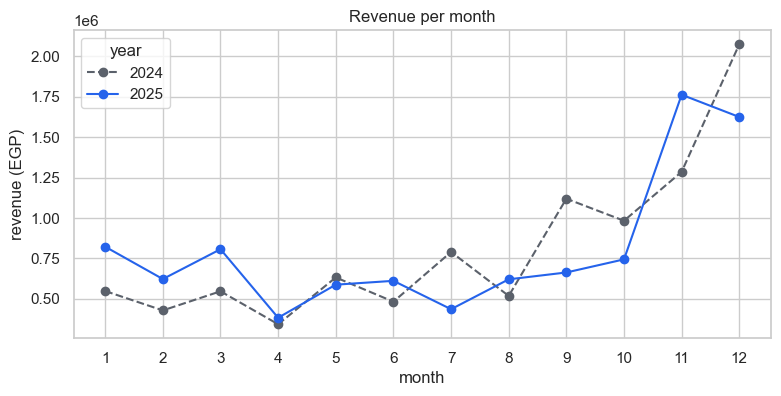

In [14]:
monthly = done.pivot_table(index=done["order_date"].dt.month, columns="year", values="revenue", aggfunc="sum")

ax = monthly.plot(marker="o", style=["--", "-"], color=["#5b616b", "#2563eb"])
ax.set(title="Revenue per month", xlabel="month", ylabel="revenue (EGP)", xticks=range(1, 13))
plt.show()

Both years peak in November and December (White Friday and New Year).
But 2025 isn't clearly above 2024. The lines cross many times. We need numbers.

## Step 5 · Analyze

The three metrics, for each year:

In [15]:
by_year = done.groupby("year").agg(
    orders=("order_id", "count"),
    revenue=("revenue", "sum"),
    median_order=("revenue", "median"),
)
by_year

,orders,revenue,median_order
year,,,
2024,496,"9,739,520.90","3,560.00"
2025,578,"9,672,801.10","3,780.00"


In [16]:
by_year.pct_change().iloc[1].map("{:+.1%}".format)

orders          +16.5%
revenue          -0.7%
median_order     +6.2%
Name: 2025, dtype: object

Three metrics, three different answers:

- **orders:** +16.5%. NileCart grew.
- **median order:** +6.2%. A typical order got a bit bigger.
- **revenue:** −0.7%. Flat.

How can there be more orders, bigger typical orders, and the same money?
A few very large orders weigh more than hundreds of small ones. Let's count them:

In [17]:
big = done[done["revenue"] > 100_000]
big.groupby("year")["revenue"].agg(["count", "sum"])

,count,sum
year,,
2024,24,"3,764,380.00"
2025,19,"2,943,390.00"


Orders above 100,000 EGP went from 24 to 19, and they brought in about 820,000 EGP less.
That alone cancels the growth of all the other orders.

## Step 6 · Communicate

> **NileCart had 17% more orders in 2025, and the typical order grew by 6%.
> Total revenue stayed flat, because the very large corporate orders (above 100,000 EGP) dropped from 24 to 19.**

Two sentences, the answer and the reason.
And a new question: *why did the large corporate orders drop?*
That's the workflow starting over from Step 1.

---
# 5️⃣ The raw tables

`sales.csv` is a ready-made table. It was built from five raw tables, joined on shared **key** columns:

| File | Rows | Key columns |
|---|---|---|
| `orders.csv` | 1,501 | `order_id`, `customer_id` → customers, `product_id` → products |
| `customers.csv` | 200 | `customer_id`, `governorate` → governorates |
| `products.csv` | 12 | `product_id` |
| `governorates.csv` | 17 | `governorate` |
| `fx_rates.csv` | 106 | `rate_date` (not used in `sales.csv`) |

In [18]:
raw = {name: pd.read_csv(DATA / f"{name}.csv") for name in ["orders", "customers", "products", "governorates", "fx_rates"]}
pd.Series({name: table.shape for name, table in raw.items()})

orders          (1501, 8)
customers        (200, 6)
products          (12, 5)
governorates      (17, 3)
fx_rates         (106, 2)
dtype: object

The raw tables have problems, on purpose. Real data always does.
A first look already shows some of them:

In [19]:
orders = raw["orders"]
orders.isna().sum()

order_id        0
order_date      0
customer_id     0
product_id      0
quantity       30
unit_price      0
discount       40
status         10
dtype: int64

In [20]:
orders["quantity"].describe()

count   1,471.00
mean        4.42
std        13.15
min        -2.00
25%         2.00
50%         4.00
75%         5.00
max       500.00
Name: quantity, dtype: float64

In [21]:
print("duplicated rows:", orders.duplicated().sum())
print("latest order date:", orders["order_date"].max())
print("customer ids not in customers.csv:", sorted(set(orders["customer_id"]) - set(raw["customers"]["customer_id"])))

duplicated rows: 1
latest order date: 2031-03-15
customer ids not in customers.csv: [901, 902]


In [22]:
raw["customers"]["governorate"].sort_values().unique()

array([' alexandria', 'Alexandria', 'Assiut', 'Aswan', 'Beheira', 'Cairo',
       'Dakahlia', 'GIZA ', 'Gharbia', 'Giza', 'Ismailia', 'Luxor',
       'Monufia', 'Port Said', 'Qalyubia', 'Sharqia', 'Sohag', 'Suez',
       'cairo'], dtype=object)

- missing values in `quantity`, `discount` and `status`,
- a quantity of −2 and another of 500,
- one duplicated row,
- an order dated 2031,
- orders from customers 901 and 902, who don't exist,
- the same governorate written in different ways (`cairo`, `GIZA `, ` alexandria`).

We fix all of these, one by one, in the *Data Cleaning* lesson.
Until then we work on the clean `sales.csv`.

---
# 🧰 Summary

| Idea | In one line |
|---|---|
| Data analysis | question → data → answer → decision |
| The workflow | Ask · Collect · Clean · Explore · Analyze · Communicate |
| Metric | decide what you measure before you answer |
| Tidy data | row = observation, column = variable, cell = one value |
| Types of data | Continuous · Discrete · Nominal · Ordinal · Datetime · Text · ID |
| dtype ≠ type | the dtype is how it's stored, the type is what it means |
| First look | `shape`, `head()`, `dtypes`, `isna().sum()` |

**Next lesson:** Light linear algebra: vectors, matrices, and a table as a matrix.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)